In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor



# **Read & Load El Data**

In [ ]:
df= pd.read_csv('/content/indian_road_accidents_passenger_level.csv')

/tmp/ipykernel_22387/1507540809.py:1: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv('/content/indian_road_accidents_passenger_level.csv')


In [ ]:
df.head()

,record_id,occupant_unique_id,crash_ref_id,occupant_seq_no,city_name,state_name,lat_coord,lon_coord,incident_year,incident_month,...,license_status,ambulance_called_flag,emergency_response_time_min,distance_to_hospital_km,total_casualties_reported,injury_outcome,hospitalized_flag,estimated_recovery_days,fatality_flag,survived
0,1,0_P1,0,1,Pune,Maharashtra,18.680827,73.930388,2023,10,...,expired,1,21.7,6.7,2,fatal,1,0,1,0
1,2,0_P2,0,2,Pune,Maharashtra,18.680827,73.930388,2023,10,...,valid,1,19.4,0.9,2,fatal,1,0,1,0
2,3,0_P3,0,3,Pune,Maharashtra,18.680827,73.930388,2023,10,...,expired,1,22.5,5.4,2,no_injury,0,0,0,1
3,4,0_P4,0,4,Pune,Maharashtra,18.680827,73.930388,2023,10,...,valid,1,20.0,3.7,2,no_injury,0,0,0,1
4,5,1_P1,1,1,Mumbai,Maharashtra,18.817732,72.790846,2023,5,...,valid,1,8.5,3.1,3,severe_injury,1,21,0,1


# **EDA**

In [ ]:
df.tail()

,record_id,occupant_unique_id,crash_ref_id,occupant_seq_no,city_name,state_name,lat_coord,lon_coord,incident_year,incident_month,...,license_status,ambulance_called_flag,emergency_response_time_min,distance_to_hospital_km,total_casualties_reported,injury_outcome,hospitalized_flag,estimated_recovery_days,fatality_flag,survived
131399,131400,19998_P3,19998,3,Kolkata,West Bengal,22.454882,88.322213,2023,3,...,expired,0,13.8,7.9,0,no_injury,0,0,0,1
131400,131401,19999_P1,19999,1,Delhi,Delhi,28.510266,77.065301,2024,7,...,valid,1,29.6,5.9,2,severe_injury,1,25,0,1
131401,131402,19999_P2,19999,2,Delhi,Delhi,28.510266,77.065301,2024,7,...,valid,0,23.1,0.7,2,minor_injury,0,5,0,1
131402,131403,19999_P3,19999,3,Delhi,Delhi,28.510266,77.065301,2024,7,...,valid,0,28.3,0.5,2,minor_injury,1,7,0,1
131403,131404,19999_P4,19999,4,Delhi,Delhi,28.510266,77.065301,2024,7,...,learner_permit,0,20.4,1.5,2,fatal,1,0,1,0


In [ ]:
df.shape

(131404, 50)

In [ ]:
df.describe()

,record_id,crash_ref_id,occupant_seq_no,lat_coord,lon_coord,incident_year,incident_month,hour_of_day,weekend_flag,is_night_time,...,passenger_age_years,airbag_deployed_flag,ambulance_called_flag,emergency_response_time_min,distance_to_hospital_km,total_casualties_reported,hospitalized_flag,estimated_recovery_days,fatality_flag,survived
count,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,...,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000,131404.000000
mean,65702.500000,10053.854053,6.825051,20.436256,78.182344,2023.177453,6.128154,11.495114,0.285760,0.416761,...,31.741043,0.107424,0.573963,14.801746,6.015229,2.113490,0.319184,4.111016,0.120735,0.879265
std,37933.211724,5767.290519,7.196367,6.163053,4.519885,0.963115,3.519261,6.942462,0.451777,0.493024,...,11.989783,0.309653,0.494501,6.990802,5.978233,1.595444,0.466162,7.507801,0.325820,0.325820
min,1.000000,0.000000,1.000000,12.800172,72.700017,2022.000000,1.000000,0.000000,0.000000,0.000000,...,3.000000,0.000000,0.000000,2.000000,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,32851.750000,5075.750000,2.000000,17.208134,73.993157,2022.000000,3.000000,5.000000,0.000000,0.000000,...,24.000000,0.000000,0.000000,9.500000,1.700000,1.000000,0.000000,0.000000,0.000000,1.000000
50%,65702.500000,10144.000000,4.000000,18.837483,77.284126,2023.000000,6.000000,12.000000,0.000000,0.000000,...,31.000000,0.000000,1.000000,14.600000,4.200000,2.000000,0.000000,0.000000,0.000000,1.000000
75%,98553.250000,15038.000000,8.000000,28.406774,80.111838,2024.000000,9.000000,18.000000,1.000000,1.000000,...,39.000000,0.000000,1.000000,19.900000,8.300000,3.000000,1.000000,5.000000,0.000000,1.000000
max,131404.000000,19999.000000,40.000000,30.799960,88.499861,2025.000000,12.000000,23.000000,1.000000,1.000000,...,85.000000,1.000000,1.000000,41.200000,45.000000,5.000000,1.000000,50.000000,1.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131404 entries, 0 to 131403
Data columns (total 50 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   record_id                    131404 non-null  int64  
 1   occupant_unique_id           131404 non-null  object 
 2   crash_ref_id                 131404 non-null  int64  
 3   occupant_seq_no              131404 non-null  int64  
 4   city_name                    131404 non-null  object 
 5   state_name                   131404 non-null  object 
 6   lat_coord                    131404 non-null  float64
 7   lon_coord                    131404 non-null  float64
 8   incident_year                131404 non-null  int64  
 9   incident_month               131404 non-null  int64  
 10  incident_time                131404 non-null  object 
 11  hour_of_day                  131404 non-null  int64  
 12  weekday_name                 131404 non-null  object 
 13 

In [ ]:
df.isnull().sum()


,0
record_id,0
occupant_unique_id,0
crash_ref_id,0
occupant_seq_no,0
city_name,0
state_name,0
lat_coord,0
lon_coord,0
incident_year,0
incident_month,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['festival_name']=df['festival_name'].fillna('No Festival')

In [ ]:
df.nunique()

,0
record_id,131404
occupant_unique_id,131404
crash_ref_id,20000
occupant_seq_no,40
city_name,8
state_name,7
lat_coord,19907
lon_coord,19927
incident_year,4
incident_month,12


In [ ]:
df['survived'].value_counts()

,count
survived,
1,115539
0,15865


In [ ]:
outliers_cols=df.select_dtypes(include=np.number).columns

outliers_cols=['speed_at_impact_kmph','passenger_age_years','emergency_response_time_min']

for i in outliers_cols:
  Q1=df[i].quantile(0.25)
  Q3=df[i].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR
  outliers = df[(df[i] < lower_bound) | (df[i] > upper_bound)]
  df[i]=np.where(df[i]>upper_bound,upper_bound,df[i])
  df[i]=np.where(df[i]<lower_bound,lower_bound,df[i])
  print(f"column '{i}': found {len(outliers)} outlier rows out of {len(df)}.")

column 'speed_at_impact_kmph': found 190 outlier rows out of 131404.
column 'passenger_age_years': found 1248 outlier rows out of 131404.
column 'emergency_response_time_min': found 87 outlier rows out of 131404.


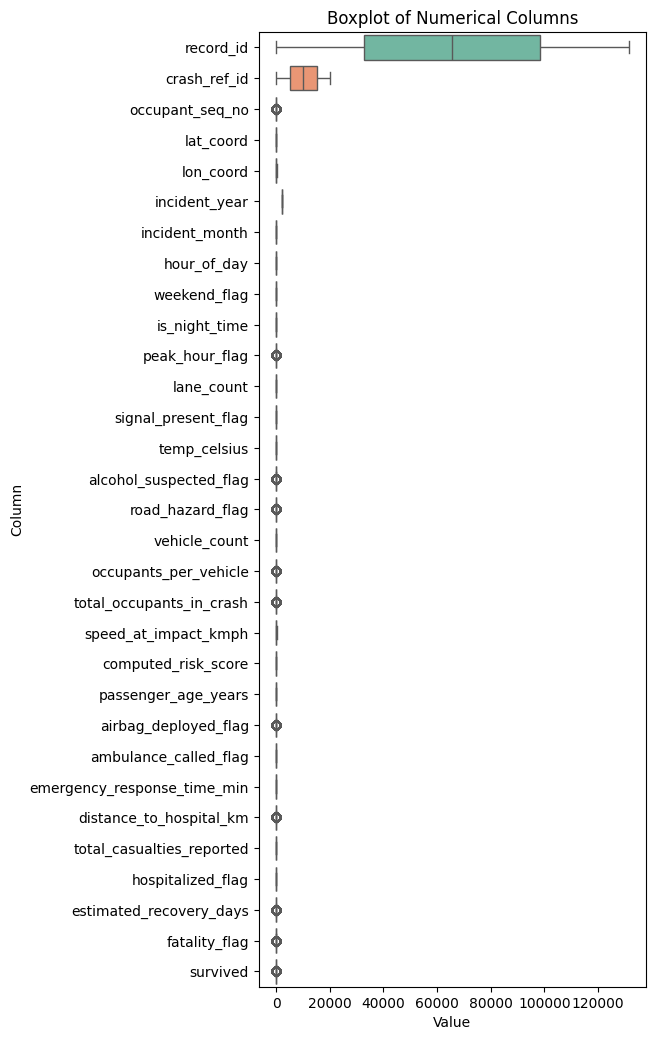

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(5, len(num_cols)*.4))
sns.boxplot(data=df[num_cols], orient ='h', palette='Set2')
plt.title('Boxplot of Numerical Columns')
plt.xlabel('Value')
plt.ylabel('Column')
plt.show()

/tmp/ipykernel_22387/2526237531.py:2: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  df_before = pd.read_csv('/content/indian_road_accidents_passenger_level.csv')


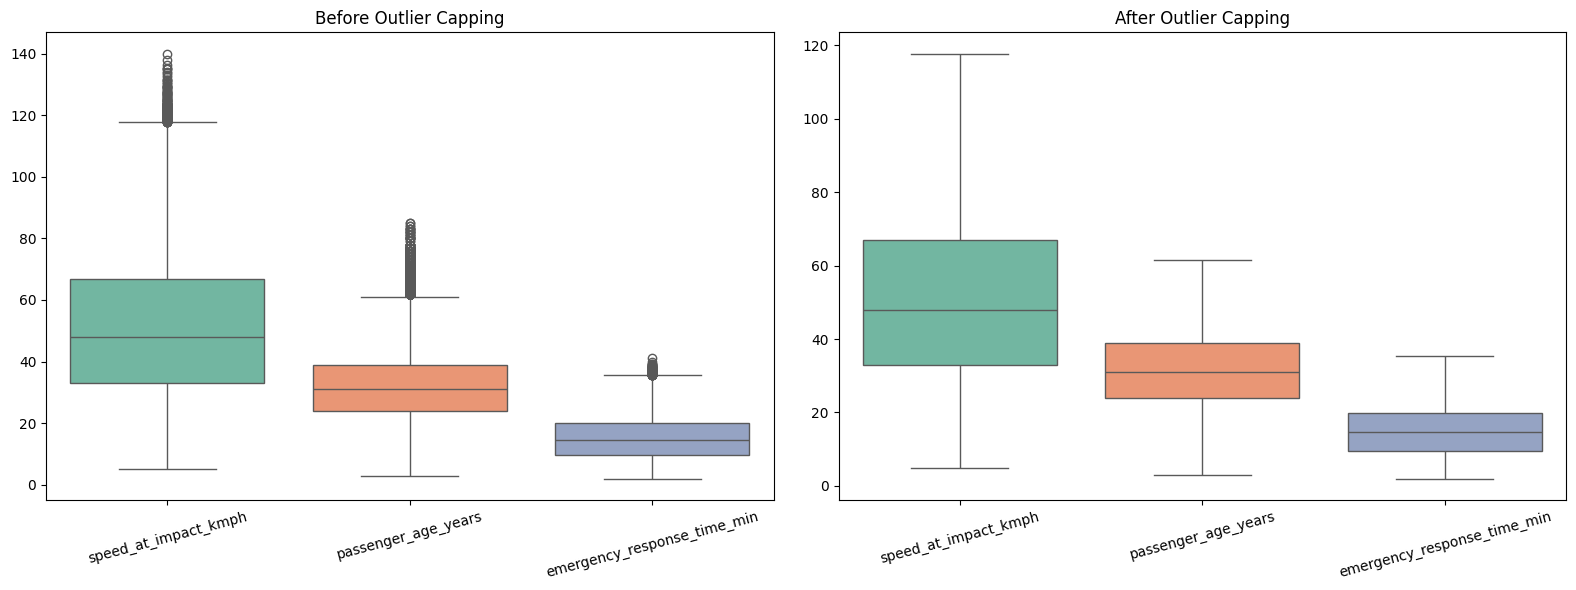

In [ ]:
# Load a fresh copy of the dataset to represent the state 'before' outlier capping
df_before = pd.read_csv('/content/indian_road_accidents_passenger_level.csv')
df_after = df

target_cols = ['speed_at_impact_kmph', 'passenger_age_years', 'emergency_response_time_min']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot for the data before capping outliers
sns.boxplot(data=df_before[target_cols], ax=axes[0], palette="Set2")
axes[0].set_title("Before Outlier Capping")
axes[0].tick_params(axis='x', rotation=15)

# Boxplot for the data after capping outliers
sns.boxplot(data=df_after[target_cols], ax=axes[1], palette="Set2")
axes[1].set_title("After Outlier Capping")
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# **Visualization**

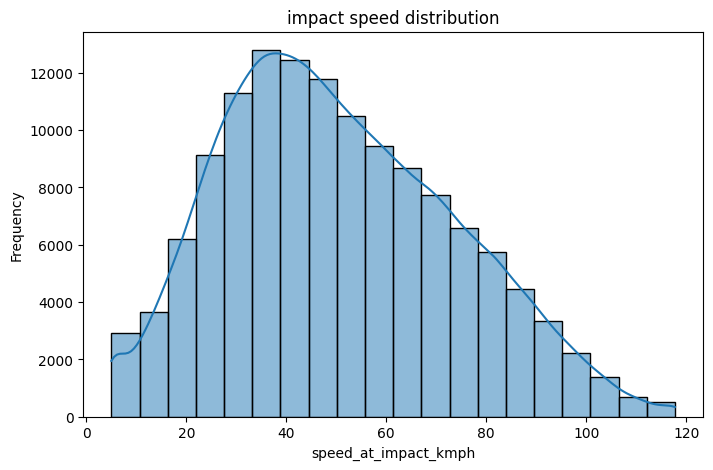

In [ ]:
plt.figure(figsize=(8,5))
if 'speed_at_impact_kmph' in df.columns:
  sns.histplot(df['speed_at_impact_kmph'],bins=20,kde=True)
  plt.title('impact speed distribution')
  plt.xlabel('speed_at_impact_kmph')
  plt.ylabel('Frequency')
  plt.show()



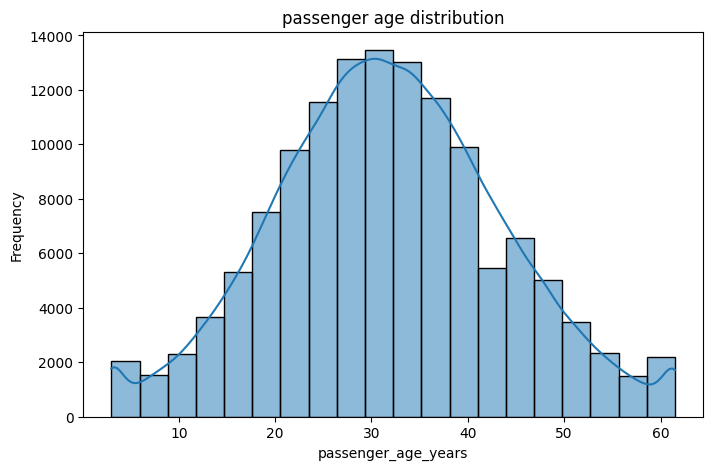

In [ ]:
plt.figure(figsize=(8,5))
if 'passenger_age_years' in df.columns:
  sns.histplot(df['passenger_age_years'],bins=20,kde=True)
  plt.title('passenger age distribution')
  plt.xlabel('passenger_age_years')
  plt.ylabel('Frequency')
  plt.show()

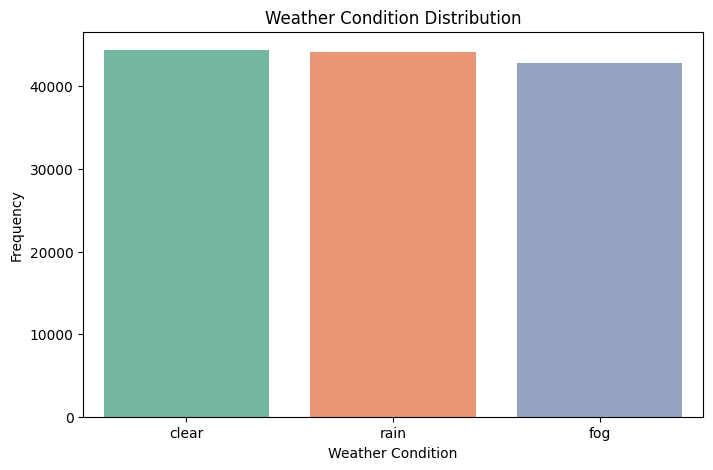

In [ ]:
plt.figure(figsize=(8,5))
if 'weather_condition' in df.columns:
  top_weather_conditions = df['weather_condition'].value_counts().head(10)
  sns.barplot(x=top_weather_conditions.index, y=top_weather_conditions.values, hue=top_weather_conditions.index, palette='Set2', legend=False)
  plt.title('Weather Condition Distribution')
  plt.xlabel('Weather Condition')
  plt.ylabel('Frequency')
  plt.show()

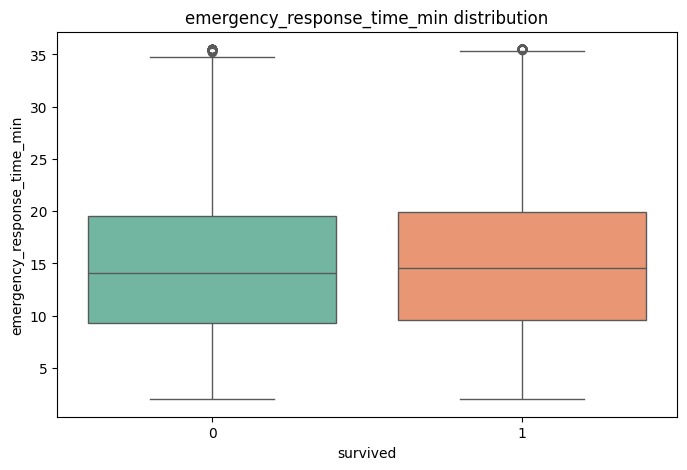

In [ ]:
plt.figure(figsize=(8,5))
if 'emergency_response_time_min' in df.columns and 'survived' in df.columns :
  sns.boxplot(data=df, x='survived', y='emergency_response_time_min', hue='survived', palette='Set2', legend=False)
  plt.title('emergency_response_time_min distribution')
  plt.xlabel('survived')
  plt.ylabel('emergency_response_time_min')
  plt.show()

# **Preprocessing**

# **Split el data**

In [ ]:
x = df.drop('survived', axis=1)
y = df['survived']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print('shape of x_train:', x_train.shape)
print('shape of x_test:', x_test.shape)

x_encoded = pd.get_dummies(x, columns=['weather_condition', 'festival_name'])
print('shape of x after encoding:', x_encoded.shape)
print('shape of y:', y.shape)

shape of x_train: (105123, 49)
shape of x_test: (26281, 49)
shape of x after encoding: (131404, 55)
shape of y: (131404,)


In [ ]:
ids_to_drop =['record_id','crash_ref_id','occupant_seq_no']

# **Handling el imbalance**

In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [ ]:
cols_to_drop = ['record_id', 'crash_ref_id', 'occupant_seq_no', 'occupant_unique_id', 'fatality_flag', 'hospitalized_flag']
x_numeric = x_encoded.drop(columns=[col for col in cols_to_drop if col in x_encoded.columns])
x_numeric = x_numeric.select_dtypes(include=[np.number])

x_train, x_test, y_train, y_test = train_test_split(x_numeric, y, test_size=0.2, random_state=42, stratify=y)

smote = SMOTE(random_state=42)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train, y_train)

print("before SMOTE - y_train value counts:\n", y_train.value_counts())
print("after SMOTE - y_train_resampled value counts:\n", y_train_resampled.value_counts())

before SMOTE - y_train value counts:
 survived
1    92431
0    12692
Name: count, dtype: int64
after SMOTE - y_train_resampled value counts:
 survived
1    92431
0    92431
Name: count, dtype: int64


# **Modeling**

In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(x_train_resampled, y_train_resampled)


RandomForestRegressor(random_state=42)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

leakage_cols = ['survived', 'fatality_flag', 'hospitalized_flag']

ids_to_drop = ['record_id', 'crash_ref_id', 'occupant_seq_no', 'occupant_unique_id', 'estimated_recovery_days']

X_clean = x_encoded.drop(columns=[col for col in (leakage_cols + ids_to_drop) if col in x_encoded.columns])
X_clean = X_clean.select_dtypes(include=[np.number])

X_train, X_test, y_train, y_test = train_test_split(X_clean, y, test_size=0.2, random_state=42, stratify=y)

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

rf_clf = RandomForestClassifier(random_state=42, n_estimators=100)
rf_clf.fit(X_train_res, y_train_res)

y_pred = rf_clf.predict(X_test)

print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.848788097865378

Classification Report:
               precision    recall  f1-score   support

           0       0.30      0.19      0.23      3173
           1       0.89      0.94      0.92     23108

    accuracy                           0.85     26281
   macro avg       0.60      0.57      0.58     26281
weighted avg       0.82      0.85      0.83     26281



Accuracy Score: 0.8673185951828317

Classification Report:
               precision    recall  f1-score   support

           0       0.37      0.14      0.20      3173
           1       0.89      0.97      0.93     23108

    accuracy                           0.87     26281
   macro avg       0.63      0.55      0.57     26281
weighted avg       0.83      0.87      0.84     26281



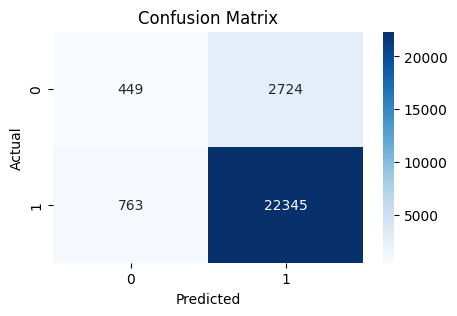

In [ ]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

xgb_clf = xgb.XGBClassifier(random_state=42, n_estimators=100)
xgb_clf.fit(X_train_res, y_train_res)

y_pred = xgb_clf.predict(X_test)

print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

plt.figure(figsize=(5, 3))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100),
    "XGBoost": xgb.XGBClassifier(random_state=42, eval_metric='logloss', n_estimators=100)
}

for name, model in models.items():
    print(f"="*40)
    print(f"Training and Evaluating: {name}")
    print(f"="*40)

    model.fit(X_train_res, y_train_res)

    y_pred = model.predict(X_test)

    print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("\n")

Training and Evaluating: Logistic Regression


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy Score: 0.7087

Classification Report:
              precision    recall  f1-score   support

           0       0.19      0.42      0.26      3173
           1       0.90      0.75      0.82     23108

    accuracy                           0.71     26281
   macro avg       0.55      0.58      0.54     26281
weighted avg       0.82      0.71      0.75     26281



Training and Evaluating: K-Nearest Neighbors
Accuracy Score: 0.6572

Classification Report:
              precision    recall  f1-score   support

           0       0.18      0.50      0.26      3173
           1       0.91      0.68      0.78     23108

    accuracy                           0.66     26281
   macro avg       0.54      0.59      0.52     26281
weighted avg       0.82      0.66      0.71     26281



Training and Evaluating: Decision Tree
Accuracy Score: 0.7816

Classification Report:
              precision    recall  f1-score   support

           0       0.20      0.28      0.24      3173
        

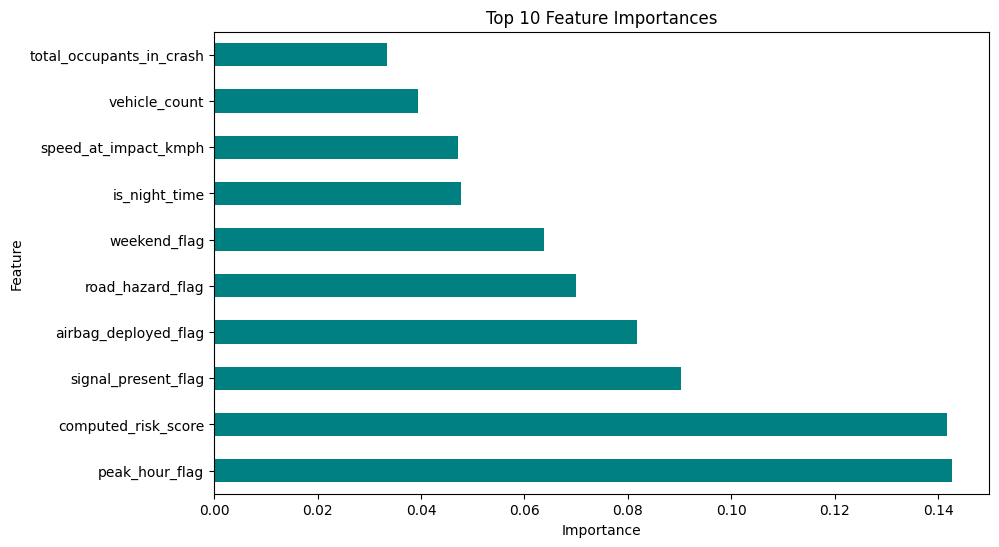

In [ ]:
feature_importances= pd.Series(xgb_clf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(10,6))
feature_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [ ]:
import joblib

joblib.dump(xgb_clf, 'traffic_accident_xgb_model.pkl')
print("model saved successfully as 'traffic_accident_xgb_model.pkl'!" )

model saved successfully as 'traffic_accident_xgb_model.pkl'!
